# RQ4 supervised bidirectional fan command-response evaluation

This notebook analyses three separately initialised command-order sequences conducted using the same pre-specified protocol: **ascending-order**, **descending-order**, and **permuted-order**. These labels describe command order rather than independent apparatus replicates. The analysis treats command creation, MQTT publication, an application-layer acknowledgement, a returned desired-PWM value, the first RPM observation satisfying the protocol threshold, three consecutive threshold-satisfying RPM observations, the scheduled RPM assessment sample, pre-specified exception conditions, and return-to-stop actions as separate observations.

Terminology is limited to what the recorded observations support. An **application-layer acknowledgement** means that a matching message reported the command as accepted; it does not by itself confirm that the fan rotated. The **RPM acceptance criterion** means that the recorded target-specific tachometer observations satisfied the pre-specified stopped or running threshold and consecutive-sample rule. The **assessment sample** is the scheduled observation recorded at least five seconds after the first threshold-satisfying RPM observation; it is not a claim that the mechanical system reached a formally modelled steady state. **Criterion met** means that a pre-specified rule was satisfied in this dataset, not that a device is universally reliable or safe.

Source labels such as `PHYSICALLY_VERIFIED`, `PASS`, and `FROZEN` are retained where required for traceability to the raw files. They are system or manifest values rather than independent research conclusions. Current, vibration RMS, and differential pressure are reported as secondary descriptive observations. The analysis is limited to the tested ROOM01 apparatus and does not establish certified safety, calibrated airflow, environmental effectiveness, autonomous control, or reliability across a wider device population.


Saved results and plots are included below; no rerun is needed to inspect them. Regeneration is optional.

Scope: three command-order sequences on the same apparatus. These are not independent apparatus replicates. No earlier campaign is included.

## 1. Pre-specified data sources and reproducibility checks

This self-contained evaluation package is pinned to the three experiment folders stored beside this notebook. It does not search for or select a newer experiment directory automatically:

- `EXP_RQ4_FINAL_EVAL_20261019_105926_099E`
- `EXP_RQ4_FINAL_EVAL_20261019_110416_F338`
- `EXP_RQ4_FINAL_EVAL_20261019_110755_CCF7`

Source files remain unchanged. Processed tables and figures are written into `RQ4_Supervised_Bidirectional_Fan_Command_Response_Evaluation_outputs` beside the notebook, keeping the source records and derived analysis together.

The manifests record `phase = EVALUATION`, `dataset_role = PRIMARY_RQ4_EVALUATION`, `protocol_status = FROZEN`, and `thresholds_frozen = true`. In this notebook, “pre-specified” describes the protocol and thresholds recorded before analysis. The stored term `FROZEN` is reported for provenance and does not itself demonstrate methodological validity or finality.


In [1]:
from pathlib import Path
from hashlib import sha256
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("ggplot")

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 240,
    "font.size": 12.5,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 16,
})

SESSION_DIR_NAMES = {
    1: "EXP_RQ4_FINAL_EVAL_20261019_105926_099E",
    2: "EXP_RQ4_FINAL_EVAL_20261019_110416_F338",
    3: "EXP_RQ4_FINAL_EVAL_20261019_110755_CCF7",
}

from pathlib import Path
import sys

REPO_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                  if (p / "notebooks").is_dir() and (p / "src" / "indoortwin" / "paths.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the repository.")
sys.path.insert(0, str(REPO_ROOT / "src"))
ROOT = REPO_ROOT / "data/rq4"
assert all((ROOT / name).is_dir() for name in SESSION_DIR_NAMES.values()), (
    f"Unexpected RQ4 evaluation package root: {ROOT}"
)
SOURCES = [ROOT / SESSION_DIR_NAMES[number] for number in (1, 2, 3)]
OUTPUT = REPO_ROOT / "results/rq4"
FIGURE_DIR = OUTPUT / "figures"
TABLE_DIR = OUTPUT / "tables"
for generated_dir in (FIGURE_DIR, TABLE_DIR):
    generated_dir.mkdir(parents=True, exist_ok=True)
    # This folder is owned by the notebook. Remove stale outputs from earlier
    # notebook versions so the deliverable contains only the current analysis.
    for generated_file in generated_dir.iterdir():
        if generated_file.is_file():
            generated_file.unlink()

REQUIRED = [
    "experiment_manifest.json", "rq4_commands.csv", "rq4_command_labels.csv",
    "rq4_verification_results.csv", "rq4_qualification.csv", "rq4_negative_checks.csv",
    "publish_log.json", "protocol_trace.json", "received_values.csv", "events.jsonl",
]
EXPECTED = {
    1: (["FAN-EXH", "FAN-IN-01", "FAN-IN-02"], [0, 30, 50, 70, 100, 0]),
    2: (["FAN-IN-01", "FAN-IN-02", "FAN-EXH"], [0, 100, 70, 50, 30, 0]),
    3: (["FAN-IN-02", "FAN-EXH", "FAN-IN-01"], [0, 50, 100, 30, 70, 0]),
}
FAN_ORDER = ["FAN-EXH", "FAN-IN-01", "FAN-IN-02"]
FAN_COLORS = {"FAN-EXH": "#c45c26", "FAN-IN-01": "#1f4e79", "FAN-IN-02": "#2f6f4e"}
SESSION_MARKERS = {1: "o", 2: "s", 3: "^"}
RUN_LABELS = {1: "Ascending-order sequence", 2: "Descending-order sequence", 3: "Permuted-order sequence"}
RUN_DESCRIPTIONS = {
    1: {"fan_order": "FAN-EXH → FAN-IN-01 → FAN-IN-02", "pwm_order": "0 → 30 → 50 → 70 → 100 → 0"},
    2: {"fan_order": "FAN-IN-01 → FAN-IN-02 → FAN-EXH", "pwm_order": "0 → 100 → 70 → 50 → 30 → 0"},
    3: {"fan_order": "FAN-IN-02 → FAN-EXH → FAN-IN-01", "pwm_order": "0 → 50 → 100 → 30 → 70 → 0"},
}
TIME_COLUMNS = [
    "created_time", "sent_time", "acknowledged_time", "physically_verified_time",
    "reference_time", "rpm_update_time", "current_update_time", "vibration_update_time",
    "delta_pressure_update_time", "rpm_check_time", "ack_time", "first_qualification_time",
    "settled_time", "received_time", "event_time",
]
STATUS_RANK = {
    "CREATED": 1, "SENT": 2, "ACKNOWLEDGED": 3, "ACK_TIMEOUT": 4,
    "PHYSICAL_TIMEOUT": 5, "REJECTED": 6, "PHYSICALLY_VERIFIED": 7,
}

def as_bool(series):
    if series.dtype == bool:
        return series
    return series.astype(str).str.strip().str.lower().isin(["true", "1"])

def parse_times(frame):
    frame = frame.copy()
    for column in TIME_COLUMNS:
        if column in frame.columns:
            frame[column] = pd.to_datetime(frame[column], utc=True, errors="coerce")
    return frame

def read_jsonl(path):
    rows = []
    with path.open("r", encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, 1):
            if line.strip():
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError as exc:
                    raise ValueError(f"Invalid JSONL at {path.name}:{line_number}") from exc
    return rows

def describe_ms(series):
    values = pd.to_numeric(series, errors="coerce").dropna()
    return {
        "n": int(values.size),
        "min_ms": round(float(values.min()), 3),
        "mean_ms": round(float(values.mean()), 3),
        "median_ms": round(float(values.median()), 3),
        "p95_ms": round(float(values.quantile(0.95)), 3),
        "max_ms": round(float(values.max()), 3),
    }

def wilson_interval(successes, total, z=1.959963984540054):
    if total == 0:
        return (np.nan, np.nan)
    p = successes / total
    denominator = 1 + z * z / total
    centre = (p + z * z / (2 * total)) / denominator
    half = z * math.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / denominator
    return centre - half, centre + half

def save_fig(fig, name):
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    plt.close("all")

print(f"Pinned data root: {ROOT}")
for source in SOURCES:
    missing = [name for name in REQUIRED if not (source / name).exists()]
    if missing:
        raise FileNotFoundError(f"{source.name} is missing: {missing}")
    print(source.name)


Pinned data root: C:\Users\AMN\Downloads\~COMP971~\tmp\Examiner evidence verification\data\rq4
EXP_RQ4_FINAL_EVAL_20261019_105926_099E
EXP_RQ4_FINAL_EVAL_20261019_110416_F338
EXP_RQ4_FINAL_EVAL_20261019_110755_CCF7


## 2. Reconstruct and evaluate each command-order sequence

Each nominal command trial must contain the recorded lifecycle events, a matching application-layer acknowledgement with accepted status, a post-acknowledgement desired-PWM observation equal to the command, three consecutive RPM observations satisfying the applicable threshold, and an assessment sample recorded at least five seconds after the first threshold-satisfying RPM observation. All RPM observations used for the decision must occur within the pre-specified 15 s observation window. The 15 s value is a protocol-specific decision window, not a universal actuation-time requirement.


In [2]:
def third_observation_time(value):
    parts = [item for item in str(value).split(";") if item.strip()]
    if len(parts) < 3:
        return pd.NaT
    return pd.to_datetime(parts[2], utc=True, errors="coerce")

def score_session(path):
    manifest = json.loads((path / "experiment_manifest.json").read_text(encoding="utf-8"))
    trace = json.loads((path / "protocol_trace.json").read_text(encoding="utf-8"))
    publishes = json.loads((path / "publish_log.json").read_text(encoding="utf-8"))
    labels = pd.read_csv(path / "rq4_command_labels.csv")
    commands = parse_times(pd.read_csv(path / "rq4_commands.csv"))
    verification = parse_times(pd.read_csv(path / "rq4_verification_results.csv"))
    qualification = parse_times(pd.read_csv(path / "rq4_qualification.csv"))
    negative = pd.read_csv(path / "rq4_negative_checks.csv")
    received = parse_times(pd.read_csv(path / "received_values.csv"))
    events = parse_times(pd.DataFrame(read_jsonl(path / "events.jsonl")))

    verification["physical_verified"] = as_bool(verification["physical_verified"])
    qualification["physical_verified"] = as_bool(qualification["physical_verified"])
    negative["passed"] = as_bool(negative["passed"])
    negative["command_created"] = as_bool(negative["command_created"])
    negative["mqtt_published"] = as_bool(negative["mqtt_published"])
    for frame in (labels, commands, verification, qualification):
        frame["pwm_pct"] = pd.to_numeric(frame["pwm_pct"], errors="raise")

    session_number = int(manifest["session"])
    expected_order, expected_pwm = EXPECTED[session_number]
    assert manifest["experiment_id"] == path.name
    assert manifest["phase"] == "EVALUATION"
    assert manifest["dataset_role"] == "PRIMARY_RQ4_EVALUATION"
    assert manifest["protocol_status"] == "FROZEN"
    assert manifest["thresholds_frozen"] is True
    assert manifest["registry_version"] == "room01-entity-registry-v1.3"
    assert manifest["result"] == "PASS" and manifest["run_mode"] == "LIVE"
    assert manifest["ack_timeout_s"] == 2 and manifest["physical_response_timeout_s"] == 15
    assert manifest["stopped_rpm_max"] == 150 and manifest["running_rpm_min"] == 300
    assert manifest["fan_order"] == expected_order
    assert [float(value) for value in manifest["sequence_pwm_pct"]] == [float(value) for value in expected_pwm]

    session = labels[labels["role"] == "SESSION"].copy()
    session["step"] = session["step_label"].str.extract(r"_(\d+)$").astype(int)
    session = session.sort_values("step")
    assert len(session) == 18 and session["step"].tolist() == list(range(1, 19))
    observed_order = list(dict.fromkeys(session["target_entity"].tolist()))
    assert observed_order == expected_order
    for target in observed_order:
        observed_pwm = session.loc[session["target_entity"] == target, "pwm_pct"].tolist()
        assert observed_pwm == [float(value) for value in expected_pwm]

    commands["status_rank"] = commands["status"].map(STATUS_RANK)
    latest = commands.sort_values(["command_id", "status_rank"]).groupby("command_id", as_index=False).tail(1)
    status_sets = commands.groupby("command_id")["status"].apply(set)
    lifecycle = session.merge(latest, on=["command_id", "target_entity", "pwm_pct"], how="left")
    lifecycle["created_stage"] = lifecycle["command_id"].map(lambda value: "CREATED" in status_sets[value])
    lifecycle["sent_stage"] = lifecycle["command_id"].map(lambda value: "SENT" in status_sets[value])
    lifecycle["acknowledged_stage"] = lifecycle["command_id"].map(lambda value: "ACKNOWLEDGED" in status_sets[value])
    lifecycle["verified_stage"] = lifecycle["command_id"].map(lambda value: "PHYSICALLY_VERIFIED" in status_sets[value])
    assert lifecycle[["created_stage", "sent_stage", "acknowledged_stage", "verified_stage"]].all().all()
    assert lifecycle["status"].eq("PHYSICALLY_VERIFIED").all()

    ack_events = events[events["event_type"].eq("COMMAND_ACK")].copy()
    ack_events = ack_events[["command_id", "target_entity", "ack_status", "applied_pwm_pct", "event_time"]]
    ack_events = ack_events.rename(columns={"event_time": "ack_event_time"})
    ack_events = ack_events.drop_duplicates("command_id", keep="last")
    lifecycle = lifecycle.merge(ack_events, on=["command_id", "target_entity"], how="left")
    lifecycle["ack_latency_ms"] = (
        lifecycle["acknowledged_time"] - lifecycle["sent_time"]
    ).dt.total_seconds() * 1000
    lifecycle["create_to_send_ms"] = (
        lifecycle["sent_time"] - lifecycle["created_time"]
    ).dt.total_seconds() * 1000
    lifecycle["applied_pwm_match"] = (
        lifecycle["ack_status"].eq("ACCEPTED")
        & lifecycle["applied_pwm_pct"].astype(float).eq(lifecycle["pwm_pct"].astype(float))
    )
    assert lifecycle["ack_latency_ms"].between(0, 2000, inclusive="left").all()
    assert lifecycle["applied_pwm_match"].all()

    scored = lifecycle.merge(qualification, on="command_id", how="left", suffixes=("", "_q"))
    scored = scored.merge(verification, on="command_id", how="left", suffixes=("", "_v"))
    scored["session"] = session_number
    scored["run_label"] = RUN_LABELS[session_number]
    scored["experiment_id"] = manifest["experiment_id"]
    scored["stable_qualification_time"] = scored["observation_times"].map(third_observation_time)
    scored["first_qualifying_sample_latency_ms"] = (
        scored["first_qualification_time"] - scored["ack_time"]
    ).dt.total_seconds() * 1000
    scored["stable_qualification_latency_ms"] = (
        scored["stable_qualification_time"] - scored["ack_time"]
    ).dt.total_seconds() * 1000
    scored["settled_verification_latency_ms"] = (
        scored["settled_time"] - scored["ack_time"]
    ).dt.total_seconds() * 1000
    scored["sent_to_settled_decision_ms"] = (
        scored["settled_time"] - scored["sent_time"]
    ).dt.total_seconds() * 1000
    scored["fan_step"] = scored.groupby("target_entity").cumcount() + 1

    def first_post_ack_pwm(row):
        values = received[
            received["entity_id"].eq(row["target_entity"])
            & received["property"].eq("pwm_desired")
            & received["received_time"].gt(row["ack_time"])
            & received["received_time"].le(row["settled_time"])
        ].sort_values("received_time")
        if values.empty:
            return pd.Series({"post_ack_pwm_desired": np.nan, "post_ack_pwm_time": pd.NaT})
        first = values.iloc[0]
        return pd.Series({
            "post_ack_pwm_desired": float(first["value"]),
            "post_ack_pwm_time": first["received_time"],
        })

    scored[["post_ack_pwm_desired", "post_ack_pwm_time"]] = scored.apply(first_post_ack_pwm, axis=1)
    scored["post_ack_pwm_match"] = scored["post_ack_pwm_desired"].eq(scored["pwm_pct"].astype(float))

    assert scored["physical_verified"].all() and scored["physical_verified_v"].all()
    assert scored["reference_basis"].eq("ACK").all()
    assert scored["rpm_evidence_status"].eq("OK").all()
    assert (scored["rpm_update_time"] > scored["reference_time"]).all()
    assert scored["post_ack_pwm_match"].all()
    assert scored["consecutive_observed"].ge(3).all()
    assert scored["stable_qualification_time"].notna().all()
    assert scored["settle_delay_s"].ge(5).all()
    assert scored["settled_verification_latency_ms"].between(0, 15000).all()
    stopped = scored["pwm_pct"].eq(0)
    assert scored.loc[stopped, "settled_rpm"].le(150).all()
    assert scored.loc[~stopped, "settled_rpm"].ge(300).all()
    assert scored.loc[stopped, "reason"].eq("RPM_BELOW_OFF_THRESHOLD").all()
    assert scored.loc[~stopped, "reason"].eq("RPM_RESPONSE_PRESENT").all()
    assert (scored["settled_rpm"] - scored["rpm"]).abs().le(0.05).all()
    assert scored["current_evidence_status"].eq("OK").all()
    assert scored["vibration_evidence_status"].eq("OK").all()
    assert scored["delta_pressure_evidence_status"].eq("OK").all()
    for target in observed_order:
        running = scored[(scored["target_entity"] == target) & (scored["pwm_pct"] > 0)].sort_values("pwm_pct")
        assert running["settled_rpm"].is_monotonic_increasing

    published_pwm = [float(json.loads(item["payload"])["pwm_pct"]) for item in publishes]
    assert 101 not in published_pwm and len(publishes) == 22

    def negative_row(check_id, label):
        match = negative[(negative["check_id"] == check_id) & (negative["step_label"] == label)]
        assert len(match) == 1
        return match.iloc[0]

    n1 = negative_row("N1_OUT_OF_RANGE_COMMAND_REQUEST", "N1_OUT_OF_RANGE_COMMAND_REQUEST")
    n2 = negative_row("N2_ACK_TIMEOUT", "N2_ACK_TIMEOUT")
    n2_recovery = negative_row("N2_ACK_TIMEOUT", "N2_RECOVERY_STOP")
    n3 = negative_row("N3_ACK_WITHOUT_ROTATION", "N3_ACK_WITHOUT_ROTATION")
    n3_recovery = negative_row("N3_ACK_WITHOUT_ROTATION", "N3_RECOVERY_STOP")
    assert n1["passed"] and not n1["command_created"] and not n1["mqtt_published"]
    n2_command = latest[latest["command_id"] == n2["command_id"]].iloc[0]
    n2_event = next(item for item in trace if item.get("event") == "N2_ACK_TIMEOUT")
    assert n2["passed"] and n2_command["status"] == "ACK_TIMEOUT" and pd.isna(n2_command["acknowledged_time"])
    assert 2 <= float(n2_event["elapsed_s"]) < 3
    n2_score = qualification[qualification["command_id"] == n2_recovery["command_id"]].iloc[0]
    assert n2_recovery["passed"] and float(n2_score["settled_rpm"]) <= 150
    n3_command = latest[latest["command_id"] == n3["command_id"]].iloc[0]
    n3_score = qualification[qualification["command_id"] == n3_recovery["command_id"]].iloc[0]
    assert n3["passed"] and n3_command["status"] == "PHYSICAL_TIMEOUT"
    assert pd.notna(n3_command["acknowledged_time"])
    assert n3_recovery["passed"] and float(n3_score["settled_rpm"]) <= 150

    baseline = float(verification.loc[verification["command_id"] == n2_recovery["command_id"], "current_a"].iloc[0])
    ack = n3_command["acknowledged_time"]
    fan = received[(received["entity_id"] == "FAN-EXH") & (received["property"].isin(["rpm", "current"]))].copy()
    fan = fan[(fan["received_time"] > ack) & (fan["received_time"] <= ack + pd.Timedelta(seconds=15))]
    paired = fan.pivot_table(index="sequence", columns="property", values="value", aggfunc="first")
    paired = paired.join(fan.groupby("sequence")["received_time"].min()).dropna(subset=["rpm"]).sort_values("received_time")
    paired["rpm"] = pd.to_numeric(paired["rpm"], errors="coerce")
    paired["current_a"] = pd.to_numeric(paired["current"], errors="coerce")
    paired["rotation"] = (paired["rpm"] >= 300) & (paired["current_a"].isna() | (paired["current_a"] > baseline))
    paired["session"] = session_number
    paired["run_label"] = RUN_LABELS[session_number]
    assert not paired["rotation"].any()

    negative = negative.copy()
    negative.insert(0, "session", session_number)
    negative.insert(1, "run_label", RUN_LABELS[session_number])
    negative.insert(2, "experiment_id", manifest["experiment_id"])
    return {
        "manifest": manifest,
        "scored": scored,
        "negative": negative,
        "paired": paired,
        "baseline": baseline,
        "n2_elapsed_s": float(n2_event["elapsed_s"]),
        "n3_recovery_rpm": float(n3_score["settled_rpm"]),
    }

campaigns = [score_session(path) for path in SOURCES]
scored = pd.concat([item["scored"] for item in campaigns], ignore_index=True)
negative = pd.concat([item["negative"] for item in campaigns], ignore_index=True)
assert len(scored) == 54 and scored["command_id"].is_unique
assert len(negative) == 15 and negative["passed"].all()
print(f"Reconstructed {len(scored)} nominal command trials and {len(negative)} exception-condition/return-to-stop records.")


Reconstructed 54 nominal command trials and 15 exception-condition/return-to-stop records.


## 3. Analysis-case table, lifecycle completion, and data-integrity checks

The analysis-case denominator is 63: 54 nominal command trials, three non-dispatched input-range checks, and six dispatched exception-condition trials. Six return-to-stop actions are reported separately and are not added to that denominator. The 101% value is an intentionally invalid input request used to test range validation; it was neither transmitted to a controller nor applied as a duty cycle.


In [3]:
scored["condition"] = np.where(
    scored["fan_step"].eq(1), "0% start",
    np.where(scored["fan_step"].eq(6), "0% return", scored["pwm_pct"].astype(int).astype(str) + "%")
)

positive_trial_results = pd.DataFrame({
    "session": scored["session"],
    "run_label": scored["run_label"],
    "experiment_id": scored["experiment_id"],
    "trial_class": "NOMINAL_COMMAND",
    "scenario_id": scored["step_label"],
    "target_entity": scored["target_entity"],
    "requested_pwm_pct": scored["pwm_pct"],
    "command_id": scored["command_id"],
    "command_created": scored["created_stage"],
    "mqtt_published": scored["sent_stage"],
    "ack_expected": True,
    "ack_received": scored["acknowledged_stage"],
    "ack_status": scored["ack_status"],
    "applied_pwm_pct": scored["applied_pwm_pct"],
    "post_ack_pwm_desired": scored["post_ack_pwm_desired"],
    "rpm_acceptance_criterion_met": scored["physical_verified"],
    "assessment_sample_rpm": scored["settled_rpm"],
    "source_final_lifecycle_state": "PHYSICALLY_VERIFIED",
    "source_expected_outcome": "PHYSICALLY_VERIFIED",
    "source_observed_outcome": "PHYSICALLY_VERIFIED",
    "criterion_met": True,
    "is_recovery": False,
})

primary_labels = ["N1_OUT_OF_RANGE_COMMAND_REQUEST", "N2_ACK_TIMEOUT", "N3_ACK_WITHOUT_ROTATION"]
primary_negative = negative[negative["step_label"].isin(primary_labels)].copy()
recovery = negative[negative["step_label"].isin(["N2_RECOVERY_STOP", "N3_RECOVERY_STOP"])].copy()
assert len(primary_negative) == 9 and len(recovery) == 6

negative_rows = []
for row in primary_negative.itertuples(index=False):
    if row.step_label == "N1_OUT_OF_RANGE_COMMAND_REQUEST":
        final_state, ack_expected, ack_received, applied_pwm, physical = "REJECTED_INPUT", False, False, np.nan, np.nan
    elif row.step_label == "N2_ACK_TIMEOUT":
        final_state, ack_expected, ack_received, applied_pwm, physical = "ACK_TIMEOUT", True, False, np.nan, False
    else:
        final_state, ack_expected, ack_received, applied_pwm, physical = "PHYSICAL_TIMEOUT", True, True, 50.0, False
    negative_rows.append({
        "session": row.session,
        "run_label": row.run_label,
        "experiment_id": row.experiment_id,
        "trial_class": "INPUT_RANGE_CHECK" if not row.mqtt_published else "DISPATCHED_EXCEPTION_CONDITION",
        "scenario_id": row.check_id,
        "target_entity": row.target_entity,
        "requested_pwm_pct": row.requested_pwm_pct,
        "command_id": row.command_id,
        "command_created": row.command_created,
        "mqtt_published": row.mqtt_published,
        "ack_expected": ack_expected,
        "ack_received": ack_received,
        "ack_status": "ACCEPTED" if ack_received else np.nan,
        "applied_pwm_pct": applied_pwm,
        "post_ack_pwm_desired": np.nan,
        "rpm_acceptance_criterion_met": physical,
        "assessment_sample_rpm": np.nan,
        "source_final_lifecycle_state": final_state,
        "source_expected_outcome": row.expected_outcome,
        "source_observed_outcome": row.observed_outcome,
        "criterion_met": row.passed,
        "is_recovery": False,
    })

trial_results = pd.concat([positive_trial_results, pd.DataFrame(negative_rows)], ignore_index=True)
assert len(trial_results) == 63
trial_results.to_csv(TABLE_DIR / "rq4_trial_results.csv", index=False)

stage_definitions = [
    ("Command record created", scored["created_stage"]),
    ("Published to MQTT", scored["sent_stage"]),
    ("Matching application acknowledgement with accepted status", scored["applied_pwm_match"]),
    ("Post-acknowledgement desired PWM equalled command", scored["post_ack_pwm_match"]),
    ("First RPM observation satisfied threshold", scored["first_qualification_time"].notna()),
    ("Three consecutive RPM observations satisfied criterion", scored["stable_qualification_time"].notna()),
    ("Assessment-sample RPM criterion met", scored["physical_verified"]),
]
positive_summary_rows = []
for stage, values in stage_definitions:
    successes = int(values.sum())
    total = int(len(values))
    lower, upper = wilson_interval(successes, total)
    positive_summary_rows.append({
        "stage": stage,
        "criteria_met_count": successes,
        "trial_count": total,
        "observed_percent": round(successes / total * 100, 1),
        "wilson_95_lower_percent": round(lower * 100, 1),
        "wilson_95_upper_percent": round(upper * 100, 1),
    })
positive_summary = pd.DataFrame(positive_summary_rows)
positive_summary.to_csv(TABLE_DIR / "rq4_nominal_trial_summary.csv", index=False)

supporting_rows = []
for label, column in [
    ("Current", "current_a"), ("Vibration RMS", "vibration_rms"), ("Differential pressure", "delta_pressure_pa")
]:
    available = int(scored[column].notna().sum())
    supporting_rows.append({
        "observation": label, "available": available, "expected": len(scored),
        "complete_percent": round(available / len(scored) * 100, 1),
    })
supporting_completeness = pd.DataFrame(supporting_rows)
supporting_completeness.to_csv(TABLE_DIR / "rq4_supporting_observation_completeness.csv", index=False)

integrity_checks = pd.DataFrame([
    ("Explicit experiment directories", len(SOURCES) == 3, 3, len(SOURCES)),
    ("Distinct manifest session identifiers", len({item["manifest"]["session"] for item in campaigns}) == 3, 3, len({item["manifest"]["session"] for item in campaigns})),
    ("Pre-specified registry version recorded consistently", all(item["manifest"]["registry_version"] == "room01-entity-registry-v1.3" for item in campaigns), "room01-entity-registry-v1.3", ", ".join(item["manifest"]["registry_version"] for item in campaigns)),
    ("Nominal command trials", len(scored) == 54, 54, len(scored)),
    ("Exception-condition checks", len(primary_negative) == 9, 9, len(primary_negative)),
    ("Return-to-stop action records", len(recovery) == 6, 6, len(recovery)),
    ("Unique nominal-trial command IDs", scored["command_id"].is_unique, 54, scored["command_id"].nunique()),
    ("Requested/applied PWM matches", scored["applied_pwm_match"].all(), 54, int(scored["applied_pwm_match"].sum())),
    ("Post-ACK desired PWM matches", scored["post_ack_pwm_match"].all(), 54, int(scored["post_ack_pwm_match"].sum())),
    ("Non-negative latency values", (scored[["ack_latency_ms", "first_qualifying_sample_latency_ms", "stable_qualification_latency_ms", "settled_verification_latency_ms", "sent_to_settled_decision_ms"]] >= 0).all().all(), "all", "all"),
    ("Input validation was not published", (~primary_negative.loc[primary_negative["check_id"].eq("N1_OUT_OF_RANGE_COMMAND_REQUEST"), "mqtt_published"]).all(), 3, int((~primary_negative.loc[primary_negative["check_id"].eq("N1_OUT_OF_RANGE_COMMAND_REQUEST"), "mqtt_published"]).sum())),
    ("All exception-condition and return-to-stop criteria met", negative["passed"].all(), 15, int(negative["passed"].sum())),
], columns=["check", "criterion_met", "expected", "observed"])
integrity_checks["status"] = np.where(integrity_checks["criterion_met"], "MET", "NOT_MET")
integrity_checks.to_csv(TABLE_DIR / "rq4_integrity_checks.csv", index=False)
assert integrity_checks["criterion_met"].all()

display(positive_summary)
display(integrity_checks[["check", "status", "expected", "observed"]])


,stage,criteria_met_count,trial_count,observed_percent,wilson_95_lower_percent,wilson_95_upper_percent
0,Command record created,54,54,100.0,93.4,100.0
1,Published to MQTT,54,54,100.0,93.4,100.0
2,Matching application acknowledgement with accepted status,54,54,100.0,93.4,100.0
3,Post-acknowledgement desired PWM equalled command,54,54,100.0,93.4,100.0
4,First RPM observation satisfied threshold,54,54,100.0,93.4,100.0
5,Three consecutive RPM observations satisfied criterion,54,54,100.0,93.4,100.0
6,Assessment-sample RPM criterion met,54,54,100.0,93.4,100.0


,check,status,expected,observed
0,Explicit experiment directories,MET,3,3
1,Distinct manifest session identifiers,MET,3,3
2,Pre-specified registry version recorded consistently,MET,room01-entity-registry-v1.3,"room01-entity-registry-v1.3, room01-entity-registry-v1.3, room01-entity-registry-v1.3"
3,Nominal command trials,MET,54,54
4,Exception-condition checks,MET,9,9
5,Return-to-stop action records,MET,6,6
6,Unique nominal-trial command IDs,MET,54,54
7,Requested/applied PWM matches,MET,54,54
8,Post-ACK desired PWM matches,MET,54,54
9,Non-negative latency values,MET,all,all


## 4. Repeatability of assessment-sample RPM by fan and commanded PWM

The principal response figure aligns observations by commanded PWM rather than by command order. Points represent observations from the individual command-order sequences. The black line shows the arithmetic mean and the error bar shows one sample standard deviation. The initial and return-to-zero observations are retained as separate protocol conditions. “Assessment-sample RPM” is used instead of “settled RPM” because no dynamic model or formal steady-state test was fitted.


In [4]:
repeatability_rows = []
for (target, condition), part in scored.groupby(["target_entity", "condition"], sort=False):
    values = part["settled_rpm"].astype(float)
    mean_value = float(values.mean())
    repeatability_rows.append({
        "target_entity": target,
        "condition": condition,
        "pwm_pct": float(part["pwm_pct"].iloc[0]),
        "n": int(values.size),
        "mean_rpm": round(mean_value, 3),
        "sd_rpm": round(float(values.std(ddof=1)), 3) if values.size > 1 else np.nan,
        "min_rpm": round(float(values.min()), 3),
        "max_rpm": round(float(values.max()), 3),
        "cv_percent": round(float(values.std(ddof=1) / mean_value * 100), 3) if mean_value > 0 and values.size > 1 else np.nan,
    })
repeatability = pd.DataFrame(repeatability_rows)
condition_order = {"0% start": 0, "30%": 1, "50%": 2, "70%": 3, "100%": 4, "0% return": 5}
repeatability["condition_order"] = repeatability["condition"].map(condition_order)
repeatability = repeatability.sort_values(["target_entity", "condition_order"]).drop(columns="condition_order")
repeatability.to_csv(TABLE_DIR / "rq4_repeatability_summary.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15.2, 5.4), sharex=True, sharey=True)
for axis, target in zip(axes, FAN_ORDER):
    fan = scored[scored["target_entity"].eq(target)]
    for session_number in (1, 2, 3):
        part = fan[fan["session"].eq(session_number)]
        axis.scatter(
            part["pwm_pct"], part["settled_rpm"], marker=SESSION_MARKERS[session_number],
            s=58, alpha=0.78, color=FAN_COLORS[target], edgecolor="white", linewidth=0.7,
        )
    grouped = fan.groupby("pwm_pct")["settled_rpm"].agg(["mean", "std"]).reindex([0, 30, 50, 70, 100])
    axis.errorbar(
        grouped.index, grouped["mean"], yerr=grouped["std"].fillna(0),
        color="#202020", marker="o", markersize=4, linewidth=1.5, capsize=3,
        label="Mean ± SD",
    )
    axis.axhline(150, color="#777777", linestyle=":", linewidth=1)
    axis.axhline(300, color="#777777", linestyle="--", linewidth=1)
    axis.set_title(target)
    axis.set_xticks([0, 30, 50, 70, 100])
    axis.set_xlabel("Commanded PWM (%)")
    axis.set_ylim(-80, 3200)
axes[0].set_ylabel("Fan speed at scheduled assessment (RPM)")
legend_handles = [
    Line2D([0], [0], marker=SESSION_MARKERS[number], color="none", markerfacecolor="#666666", markeredgecolor="white", markersize=7, label=RUN_LABELS[number])
    for number in (1, 2, 3)
] + [Line2D([0], [0], color="#202020", marker="o", label="Mean ± SD")]
fig.legend(handles=legend_handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.01))
fig.suptitle("Assessment-sample fan speed across three command-order sequences", y=1.12)
fig.tight_layout()
save_fig(fig, "figure_rq4_pwm_rpm_repeatability")

display(repeatability.round(3))


,target_entity,condition,pwm_pct,n,mean_rpm,sd_rpm,min_rpm,max_rpm,cv_percent
0,FAN-EXH,0% start,0.0,3,0.000,0.000,0.0,0.0,NaN
1,FAN-EXH,30%,30.0,3,1013.700,28.898,994.2,1046.9,2.851
2,FAN-EXH,50%,50.0,3,1605.933,19.030,1585.1,1622.4,1.185
3,FAN-EXH,70%,70.0,3,2158.767,23.908,2134.5,2182.3,1.108
4,FAN-EXH,100%,100.0,3,2880.633,44.851,2830.7,2917.5,1.557
5,FAN-EXH,0% return,0.0,3,0.000,0.000,0.0,0.0,NaN
6,FAN-IN-01,0% start,0.0,3,0.000,0.000,0.0,0.0,NaN
7,FAN-IN-01,30%,30.0,3,1021.467,29.696,990.0,1049.0,2.907
8,FAN-IN-01,50%,50.0,3,1635.833,17.876,1620.8,1655.6,1.093
9,FAN-IN-01,70%,70.0,3,2165.033,40.168,2140.8,2211.4,1.855


## 5. Observed timing distributions

Application-layer acknowledgement time and tachometer-response time are reported separately because an acknowledgement does not demonstrate physical actuation. The first threshold-satisfying RPM observation, the third consecutive threshold-satisfying observation, and the scheduled assessment sample are distinct protocol events. The reported p95 is the empirical 95th percentile calculated with pandas linear interpolation; p99 is not introduced. The 2 s acknowledgement window and 15 s RPM-response window are pre-specified decision rules for this experiment, not general performance standards for actuation systems.


In [5]:
latency_measures = {
    "create_to_send": "create_to_send_ms",
    "sent_to_ack": "ack_latency_ms",
    "ack_to_first_threshold_sample": "first_qualifying_sample_latency_ms",
    "ack_to_third_consecutive_threshold_sample": "stable_qualification_latency_ms",
    "ack_to_assessment_sample": "settled_verification_latency_ms",
    "sent_to_assessment_decision": "sent_to_settled_decision_ms",
}
latency_rows = []
for scope_type, scopes in [
    ("all", [("all", scored)]),
    ("sequence", [(RUN_LABELS[number], scored[scored["session"].eq(number)]) for number in (1, 2, 3)]),
    ("fan", [(target, scored[scored["target_entity"].eq(target)]) for target in FAN_ORDER]),
]:
    for scope, part in scopes:
        for measure, column in latency_measures.items():
            latency_rows.append({"scope_type": scope_type, "scope": scope, "measure": measure, **describe_ms(part[column])})
latency_summary = pd.DataFrame(latency_rows)
latency_summary.to_csv(TABLE_DIR / "rq4_latency_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14.6, 6.2), gridspec_kw={"width_ratios": [0.9, 2.0]})
rng = np.random.default_rng(17)

ack_seconds = scored["ack_latency_ms"] / 1000
axes[0].boxplot([ack_seconds], positions=[1], widths=0.35, showfliers=False, patch_artist=True,
                boxprops={"facecolor": "#d9e6f2", "edgecolor": "#1f4e79"},
                medianprops={"color": "#202020", "linewidth": 1.5})
for target_index, target in enumerate(FAN_ORDER):
    values = scored.loc[scored["target_entity"].eq(target), "ack_latency_ms"] / 1000
    jitter = rng.normal(0, 0.035, len(values)) + (target_index - 1) * 0.055
    axes[0].scatter(np.ones(len(values)) + jitter, values, s=24, alpha=0.7, color=FAN_COLORS[target])
axes[0].scatter(1, ack_seconds.quantile(0.95), marker="D", s=55, color="#b22222", zorder=5)
axes[0].set_xticks([1], ["Command transmission →\napplication acknowledgement"])
axes[0].set_ylabel("Observed interval (s)")
axes[0].set_ylim(0, max(0.65, float(ack_seconds.max()) * 1.18))
axes[0].set_title("Application acknowledgement")
axes[0].text(0.5, 0.96, "Two-second acknowledgement criterion\n(outside plotted range)", transform=axes[0].transAxes,
             ha="center", va="top", fontsize=11.5)

physical_columns = [
    ("First qualifying\nRPM observation", "first_qualifying_sample_latency_ms"),
    ("Third consecutive\nqualifying observation", "stable_qualification_latency_ms"),
    ("Scheduled assessment\nobservation", "settled_verification_latency_ms"),
]
physical_values = [scored[column] / 1000 for _, column in physical_columns]
axes[1].boxplot(physical_values, positions=[1, 2, 3], widths=0.46, showfliers=False, patch_artist=True,
                boxprops={"facecolor": "#e4ece7", "edgecolor": "#2f6f4e"},
                medianprops={"color": "#202020", "linewidth": 1.5})
for position, (_, column) in enumerate(physical_columns, 1):
    for target_index, target in enumerate(FAN_ORDER):
        values = scored.loc[scored["target_entity"].eq(target), column] / 1000
        jitter = rng.normal(0, 0.035, len(values)) + (target_index - 1) * 0.055
        axes[1].scatter(np.full(len(values), position) + jitter, values, s=24, alpha=0.7, color=FAN_COLORS[target])
    axes[1].scatter(position, (scored[column] / 1000).quantile(0.95), marker="D", s=55, color="#b22222", zorder=5)
axes[1].axhline(15, color="#555555", linestyle="--", linewidth=1.2)
axes[1].set_xticks([1, 2, 3], [label for label, _ in physical_columns])
axes[1].set_ylabel("Time after acknowledgement (s)")
axes[1].set_ylim(0, 15.8)
axes[1].set_title("Observed tachometer-response intervals")

handles = [Line2D([0], [0], marker="o", color="none", markerfacecolor=FAN_COLORS[target], markersize=7, label=target) for target in FAN_ORDER]
handles.append(Line2D([0], [0], marker="D", color="none", markerfacecolor="#b22222", markersize=7, label="95th percentile"))
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Command acknowledgement and measured fan-response timing", y=1.10)
fig.tight_layout()
save_fig(fig, "figure_rq4_latency_distributions")

display(latency_summary[latency_summary["scope_type"].eq("all")].round(3))


,scope_type,scope,measure,n,min_ms,mean_ms,median_ms,p95_ms,max_ms
0,all,all,create_to_send,54,0.000,0.336,0.000,1.014,1.506
1,all,all,sent_to_ack,54,136.113,263.882,256.986,392.459,488.789
2,all,all,ack_to_first_threshold_sample,54,467.671,1099.664,824.572,1926.733,2117.103
3,all,all,ack_to_third_consecutive_threshold_sample,54,2442.446,3190.615,2893.546,4067.552,5106.922
4,all,all,ack_to_assessment_sample,54,5631.245,6605.328,6668.484,7970.859,8801.708
5,all,all,sent_to_assessment_decision,54,6018.066,6869.210,6945.978,8214.140,9131.497


## 6. Exception-condition checks and return-to-stop actions

N1, N2, and N3 are reported with separate denominators. N1 evaluates local input-range validation and does not dispatch a command. N2 dispatches a valid 0% request while the controller is offline and evaluates whether a matching acknowledgement is absent within the pre-specified 2 s window. N3 dispatches a 50% request while electrical power to FAN-EXH is disconnected and evaluates whether the application acknowledgement is distinguishable from a sustained tachometer response. Subsequent return-to-stop actions are reported separately rather than counted as additional exception-condition trials.


In [6]:
negative_path_results = primary_negative[[
    "session", "run_label", "experiment_id", "check_id", "step_label", "target_entity", "requested_pwm_pct",
    "command_id", "command_created", "mqtt_published", "expected_outcome", "observed_outcome", "passed", "detail",
]].copy()
exception_descriptions = {
    "N1_OUT_OF_RANGE_COMMAND_REQUEST": "Out-of-range request rejected locally; no MQTT publication",
    "N2_ACK_TIMEOUT": "No matching application acknowledgement within the pre-specified 2 s window",
    "N3_ACK_WITHOUT_ROTATION": "Application acknowledgement received; three-sample RPM criterion not met within 15 s",
}
negative_path_results["reporting_interpretation"] = negative_path_results["check_id"].map(exception_descriptions)
negative_path_results = negative_path_results.rename(columns={
    "expected_outcome": "source_expected_outcome",
    "observed_outcome": "source_observed_outcome",
    "passed": "criterion_met",
})
negative_path_results.to_csv(TABLE_DIR / "rq4_exception_condition_results.csv", index=False)

recovery_summary = recovery[[
    "session", "run_label", "experiment_id", "check_id", "step_label", "target_entity", "requested_pwm_pct",
    "command_id", "expected_outcome", "observed_outcome", "passed", "detail",
]].copy()
recovery_summary = recovery_summary.rename(columns={
    "expected_outcome": "source_expected_outcome",
    "observed_outcome": "source_observed_outcome",
    "passed": "criterion_met",
})
recovery_summary["reporting_interpretation"] = "Return-to-stop RPM criterion met"
recovery_summary.to_csv(TABLE_DIR / "rq4_recovery_summary.csv", index=False)

fig, axes = plt.subplots(2, 3, figsize=(14.8, 7.8), sharey="row")
for column, item in enumerate(campaigns):
    paired = item["paired"].copy()
    elapsed = (paired["received_time"] - paired["received_time"].iloc[0]).dt.total_seconds()
    axes[0, column].plot(elapsed, paired["rpm"], color=FAN_COLORS["FAN-EXH"], linewidth=1.4, marker="o", markersize=4)
    high_unclassified = paired["rpm"].ge(300) & ~paired["rotation"]
    if high_unclassified.any():
        axes[0, column].scatter(elapsed[high_unclassified], paired.loc[high_unclassified, "rpm"],
                                facecolors="none", edgecolors="#b22222", s=80, linewidth=1.6, zorder=5)
    axes[0, column].axhline(300, color="#666666", linestyle="--", linewidth=1)
    axes[0, column].set_title(RUN_LABELS[int(item['manifest']['session'])])
    axes[0, column].text(0.98, 0.91, "Required RPM response not recorded",
                         transform=axes[0, column].transAxes,
                         ha="right", va="top", fontsize=10.5)
    axes[1, column].plot(elapsed, paired["current_a"], color="#1f4e79", linewidth=1.4, marker="o", markersize=4)
axes[0, 0].set_ylabel("FAN-EXH speed (RPM)")
axes[1, 0].set_ylabel("FAN-EXH current (A)")
fig.supxlabel("Time after acknowledgement of 50% command (s)", y=0.02)
fig.suptitle("Application acknowledgement without measured fan rotation", y=1.02)
fig.tight_layout(rect=[0, 0.05, 1, 0.97])
save_fig(fig, "figure_rq4_ack_without_rotation")

display(negative_path_results[["run_label", "check_id", "reporting_interpretation", "criterion_met"]])
display(recovery_summary[["run_label", "step_label", "reporting_interpretation", "criterion_met"]])


,run_label,check_id,reporting_interpretation,criterion_met
0,Ascending-order sequence,N1_OUT_OF_RANGE_COMMAND_REQUEST,Out-of-range request rejected locally; no MQTT publication,True
1,Ascending-order sequence,N2_ACK_TIMEOUT,No matching application acknowledgement within the pre-specified 2 s window,True
3,Ascending-order sequence,N3_ACK_WITHOUT_ROTATION,Application acknowledgement received; three-sample RPM criterion not met within 15 s,True
5,Descending-order sequence,N1_OUT_OF_RANGE_COMMAND_REQUEST,Out-of-range request rejected locally; no MQTT publication,True
6,Descending-order sequence,N2_ACK_TIMEOUT,No matching application acknowledgement within the pre-specified 2 s window,True
8,Descending-order sequence,N3_ACK_WITHOUT_ROTATION,Application acknowledgement received; three-sample RPM criterion not met within 15 s,True
10,Permuted-order sequence,N1_OUT_OF_RANGE_COMMAND_REQUEST,Out-of-range request rejected locally; no MQTT publication,True
11,Permuted-order sequence,N2_ACK_TIMEOUT,No matching application acknowledgement within the pre-specified 2 s window,True
13,Permuted-order sequence,N3_ACK_WITHOUT_ROTATION,Application acknowledgement received; three-sample RPM criterion not met within 15 s,True


,run_label,step_label,reporting_interpretation,criterion_met
2,Ascending-order sequence,N2_RECOVERY_STOP,Return-to-stop RPM criterion met,True
4,Ascending-order sequence,N3_RECOVERY_STOP,Return-to-stop RPM criterion met,True
7,Descending-order sequence,N2_RECOVERY_STOP,Return-to-stop RPM criterion met,True
9,Descending-order sequence,N3_RECOVERY_STOP,Return-to-stop RPM criterion met,True
12,Permuted-order sequence,N2_RECOVERY_STOP,Return-to-stop RPM criterion met,True
14,Permuted-order sequence,N3_RECOVERY_STOP,Return-to-stop RPM criterion met,True


## 7. Secondary descriptive observations

Current, vibration RMS, and differential pressure are retained as secondary descriptive measurements. They are not substituted for target-specific tachometer observations, and no causal, diagnostic, or control-performance claim is inferred from them. Differential pressure is not interpreted as calibrated airflow. The figure is therefore intended for an appendix rather than as a principal RQ4 result.


In [7]:
fig, axes = plt.subplots(3, 1, figsize=(9.5, 8.0), sharex=True)
for target in FAN_ORDER:
    fan = scored[scored["target_entity"].eq(target)]
    axes[0].scatter(fan["pwm_pct"], fan["current_a"], color=FAN_COLORS[target], s=30, alpha=0.75, label=target)
    axes[1].scatter(fan["pwm_pct"], fan["vibration_rms"], color=FAN_COLORS[target], s=30, alpha=0.75)
    axes[2].scatter(fan["pwm_pct"], fan["delta_pressure_pa"], color=FAN_COLORS[target], s=30, alpha=0.75)
axes[0].set_ylabel("Current (A)")
axes[1].set_ylabel("Vibration RMS (g)")
axes[2].set_ylabel("Differential pressure (Pa)")
axes[2].set_xlabel("Commanded PWM (%)")
axes[0].legend(loc="upper left", ncol=3, frameon=False)
fig.suptitle("Secondary sensor observations at the RPM assessment sample", y=1.01, fontsize=13)
fig.tight_layout()
save_fig(fig, "figure_rq4_appendix_supporting_observations")

display(supporting_completeness)


,observation,available,expected,complete_percent
0,Current,54,54,100.0
1,Vibration RMS,54,54,100.0
2,Differential pressure,54,54,100.0


## 8. RQ4 results and scope of inference

The text below is generated from the processed tables. Counts and descriptive intervals summarise repeated observations from the same apparatus. They are not estimates of reliability for a wider population of fans, controllers, rooms, or buildings.


In [8]:
overall_latency = latency_summary[
    latency_summary["scope_type"].eq("all") & latency_summary["scope"].eq("all")
].set_index("measure")
running_repeatability = repeatability[repeatability["pwm_pct"].gt(0)]
cv_min = float(running_repeatability["cv_percent"].min())
cv_max = float(running_repeatability["cv_percent"].max())
nominal_met = int(scored["physical_verified"].sum())
nominal_total = int(len(scored))
nominal_lower, nominal_upper = wilson_interval(nominal_met, nominal_total)

def measure_value(measure, field):
    return float(overall_latency.loc[measure, field])

chapter_text = f"""### Chapter-ready RQ4 result

Across the ascending-order, descending-order and permuted-order sequences, all {nominal_total} nominal command trials produced (i) a matching application-layer acknowledgement reporting accepted status, (ii) a post-acknowledgement desired-PWM observation equal to the command, (iii) three consecutive target-specific RPM observations satisfying the pre-specified criterion, and (iv) an assessment-sample RPM satisfying that criterion ({nominal_met}/{nominal_total}). These sequence labels describe command order and do not imply independent apparatus replicates. An acknowledgement indicates that the command was accepted at the application layer; the tachometer observations provide the separate measure of fan response.

The 95th percentile was {measure_value('sent_to_ack', 'p95_ms') / 1000:.3f} s from command transmission to the matching acknowledgement, {measure_value('ack_to_first_threshold_sample', 'p95_ms') / 1000:.3f} s from acknowledgement to the first threshold-satisfying RPM observation, {measure_value('ack_to_third_consecutive_threshold_sample', 'p95_ms') / 1000:.3f} s from acknowledgement to the third consecutive threshold-satisfying observation, and {measure_value('ack_to_assessment_sample', 'p95_ms') / 1000:.3f} s from acknowledgement to the scheduled assessment sample. The maximum acknowledgement-to-assessment-sample interval was {measure_value('ack_to_assessment_sample', 'max_ms') / 1000:.3f} s, which was inside the pre-specified 15 s observation window. The 2 s acknowledgement window and 15 s RPM-response window are experiment-specific decision rules rather than universal actuation requirements.

For non-zero command levels, the coefficient of variation of assessment-sample RPM across the three command-order sequences ranged from {cv_min:.3f}% to {cv_max:.3f}% among the tested fan–PWM combinations. Within each sequence and fan, assessment-sample RPM increased across the tested command levels from 30% to 100%; the initial and return-to-zero observations were 0 RPM. The intentionally invalid 101% input request was rejected locally before command creation or MQTT publication in 3/3 checks and was never applied as a duty cycle. The controller-offline condition produced no matching acknowledgement within the pre-specified 2 s window in 3/3 checks. With FAN-EXH electrical power disconnected, a matching application acknowledgement was observed, but the three-consecutive-sample RPM criterion was not satisfied within 15 s in 3/3 checks. All six subsequent return-to-stop actions satisfied their recorded RPM criterion.

These observations show consistent command traceability and target-specific RPM response within the tested ROOM01 apparatus. The results apply to the stated protocol and installed equipment.
"""
display(Markdown(chapter_text))
(OUTPUT / "rq4_chapter_5_results.md").write_text(chapter_text, encoding="utf-8")

summary = {
    "source_dataset_package": ROOT.name,
    "source_session_identifiers": [1, 2, 3],
    "reporting_sequences": [
        {"source_session": number, "label": RUN_LABELS[number], **RUN_DESCRIPTIONS[number]}
        for number in (1, 2, 3)
    ],
    "experiment_ids": [item["manifest"]["experiment_id"] for item in campaigns],
    "phase_as_recorded": "EVALUATION",
    "dataset_role_as_recorded": "PRIMARY_RQ4_EVALUATION",
    "protocol_status_as_recorded": "FROZEN",
    "registry_version": "room01-entity-registry-v1.3",
    "nominal_trials_meeting_full_criterion": nominal_met,
    "nominal_command_trials": nominal_total,
    "descriptive_nominal_completion_wilson_95_percent": [round(nominal_lower * 100, 3), round(nominal_upper * 100, 3)],
    "timing_intervals_ms": {
        measure: {field: float(row[field]) if field != "n" else int(row[field]) for field in ["n", "min_ms", "mean_ms", "median_ms", "p95_ms", "max_ms"]}
        for measure, row in overall_latency.iterrows()
    },
    "assessment_sample_rpm_cv_percent_for_nonzero_commands": {"min": round(cv_min, 3), "max": round(cv_max, 3)},
    "exception_condition_checks_meeting_expected_criterion": int(primary_negative["passed"].sum()),
    "exception_condition_checks": int(len(primary_negative)),
    "return_to_stop_actions_meeting_expected_criterion": int(recovery["passed"].sum()),
    "return_to_stop_actions": int(len(recovery)),
    "secondary_observation_completeness": supporting_completeness.to_dict(orient="records"),
    "scope_note": "Repeated observations from one apparatus; not a population-level reliability estimate.",
}
(OUTPUT / "rq4_bidirectional_fan_command_response_evaluation_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

table_5_7 = scored[[
    "session", "run_label", "experiment_id", "step", "step_label", "target_entity", "pwm_pct", "command_id",
    "applied_pwm_pct", "post_ack_pwm_desired", "settled_rpm", "reason", "create_to_send_ms",
    "ack_latency_ms", "first_qualifying_sample_latency_ms", "stable_qualification_latency_ms",
    "settled_verification_latency_ms", "sent_to_settled_decision_ms", "settle_delay_s",
    "consecutive_observed", "current_a", "vibration_rms", "delta_pressure_pa",
]].rename(columns={
    "settled_rpm": "assessment_sample_rpm",
    "first_qualifying_sample_latency_ms": "ack_to_first_threshold_sample_ms",
    "stable_qualification_latency_ms": "ack_to_third_consecutive_threshold_sample_ms",
    "settled_verification_latency_ms": "ack_to_assessment_sample_ms",
    "sent_to_settled_decision_ms": "sent_to_assessment_decision_ms",
    "settle_delay_s": "assessment_delay_s",
})
table_5_7.to_csv(TABLE_DIR / "table_5_7_command_response.csv", index=False)

manifest_rows = []
manifest_targets = []
for source in SOURCES:
    manifest_targets.extend(source / name for name in REQUIRED)
manifest_targets.extend(sorted(TABLE_DIR.glob("*.csv")))
manifest_targets.extend(FIGURE_DIR / name for name in ("figure_rq4_pwm_rpm_repeatability.png", "figure_rq4_latency_distributions.png", "figure_rq4_ack_without_rotation.png"))
manifest_targets.extend([
    FIGURE_DIR / "figure_rq4_appendix_supporting_observations.png",
    OUTPUT / "rq4_bidirectional_fan_command_response_evaluation_summary.json",
    OUTPUT / "rq4_chapter_5_results.md",
])
for path in manifest_targets:
    if path.exists():
        manifest_rows.append({
            "relative_path": path.relative_to(REPO_ROOT).as_posix(),
            "size_bytes": path.stat().st_size,
            "sha256": sha256(path.read_bytes()).hexdigest(),
        })
file_manifest = pd.DataFrame(manifest_rows).drop_duplicates("relative_path").sort_values("relative_path")
file_manifest.to_csv(OUTPUT / "file_manifest.csv", index=False)

print("Updated tables:", len(list(TABLE_DIR.glob("*.csv"))))
print("Updated principal figures:", 3)
print("All data-integrity criteria: MET")


### Chapter-ready RQ4 result

Across the ascending-order, descending-order and permuted-order sequences, all 54 nominal command trials produced (i) a matching application-layer acknowledgement reporting accepted status, (ii) a post-acknowledgement desired-PWM observation equal to the command, (iii) three consecutive target-specific RPM observations satisfying the pre-specified criterion, and (iv) an assessment-sample RPM satisfying that criterion (54/54). These sequence labels describe command order and do not imply independent apparatus replicates. An acknowledgement indicates that the command was accepted at the application layer; the tachometer observations provide the separate measure of fan response.

The 95th percentile was 0.392 s from command transmission to the matching acknowledgement, 1.927 s from acknowledgement to the first threshold-satisfying RPM observation, 4.068 s from acknowledgement to the third consecutive threshold-satisfying observation, and 7.971 s from acknowledgement to the scheduled assessment sample. The maximum acknowledgement-to-assessment-sample interval was 8.802 s, which was inside the pre-specified 15 s observation window. The 2 s acknowledgement window and 15 s RPM-response window are experiment-specific decision rules rather than universal actuation requirements.

For non-zero command levels, the coefficient of variation of assessment-sample RPM across the three command-order sequences ranged from 0.283% to 2.907% among the tested fan–PWM combinations. Within each sequence and fan, assessment-sample RPM increased across the tested command levels from 30% to 100%; the initial and return-to-zero observations were 0 RPM. The intentionally invalid 101% input request was rejected locally before command creation or MQTT publication in 3/3 checks and was never applied as a duty cycle. The controller-offline condition produced no matching acknowledgement within the pre-specified 2 s window in 3/3 checks. With FAN-EXH electrical power disconnected, a matching application acknowledgement was observed, but the three-consecutive-sample RPM criterion was not satisfied within 15 s in 3/3 checks. All six subsequent return-to-stop actions satisfied their recorded RPM criterion.

These observations show consistent command traceability and target-specific RPM response within the tested ROOM01 apparatus. The results apply to the stated protocol and installed equipment.


Updated tables: 9
Updated principal figures: 3
All data-integrity criteria: MET


## Saved evidence plots

These are the evaluated plots from the same recorded data and results calculated above.

### Fan speed across command orders

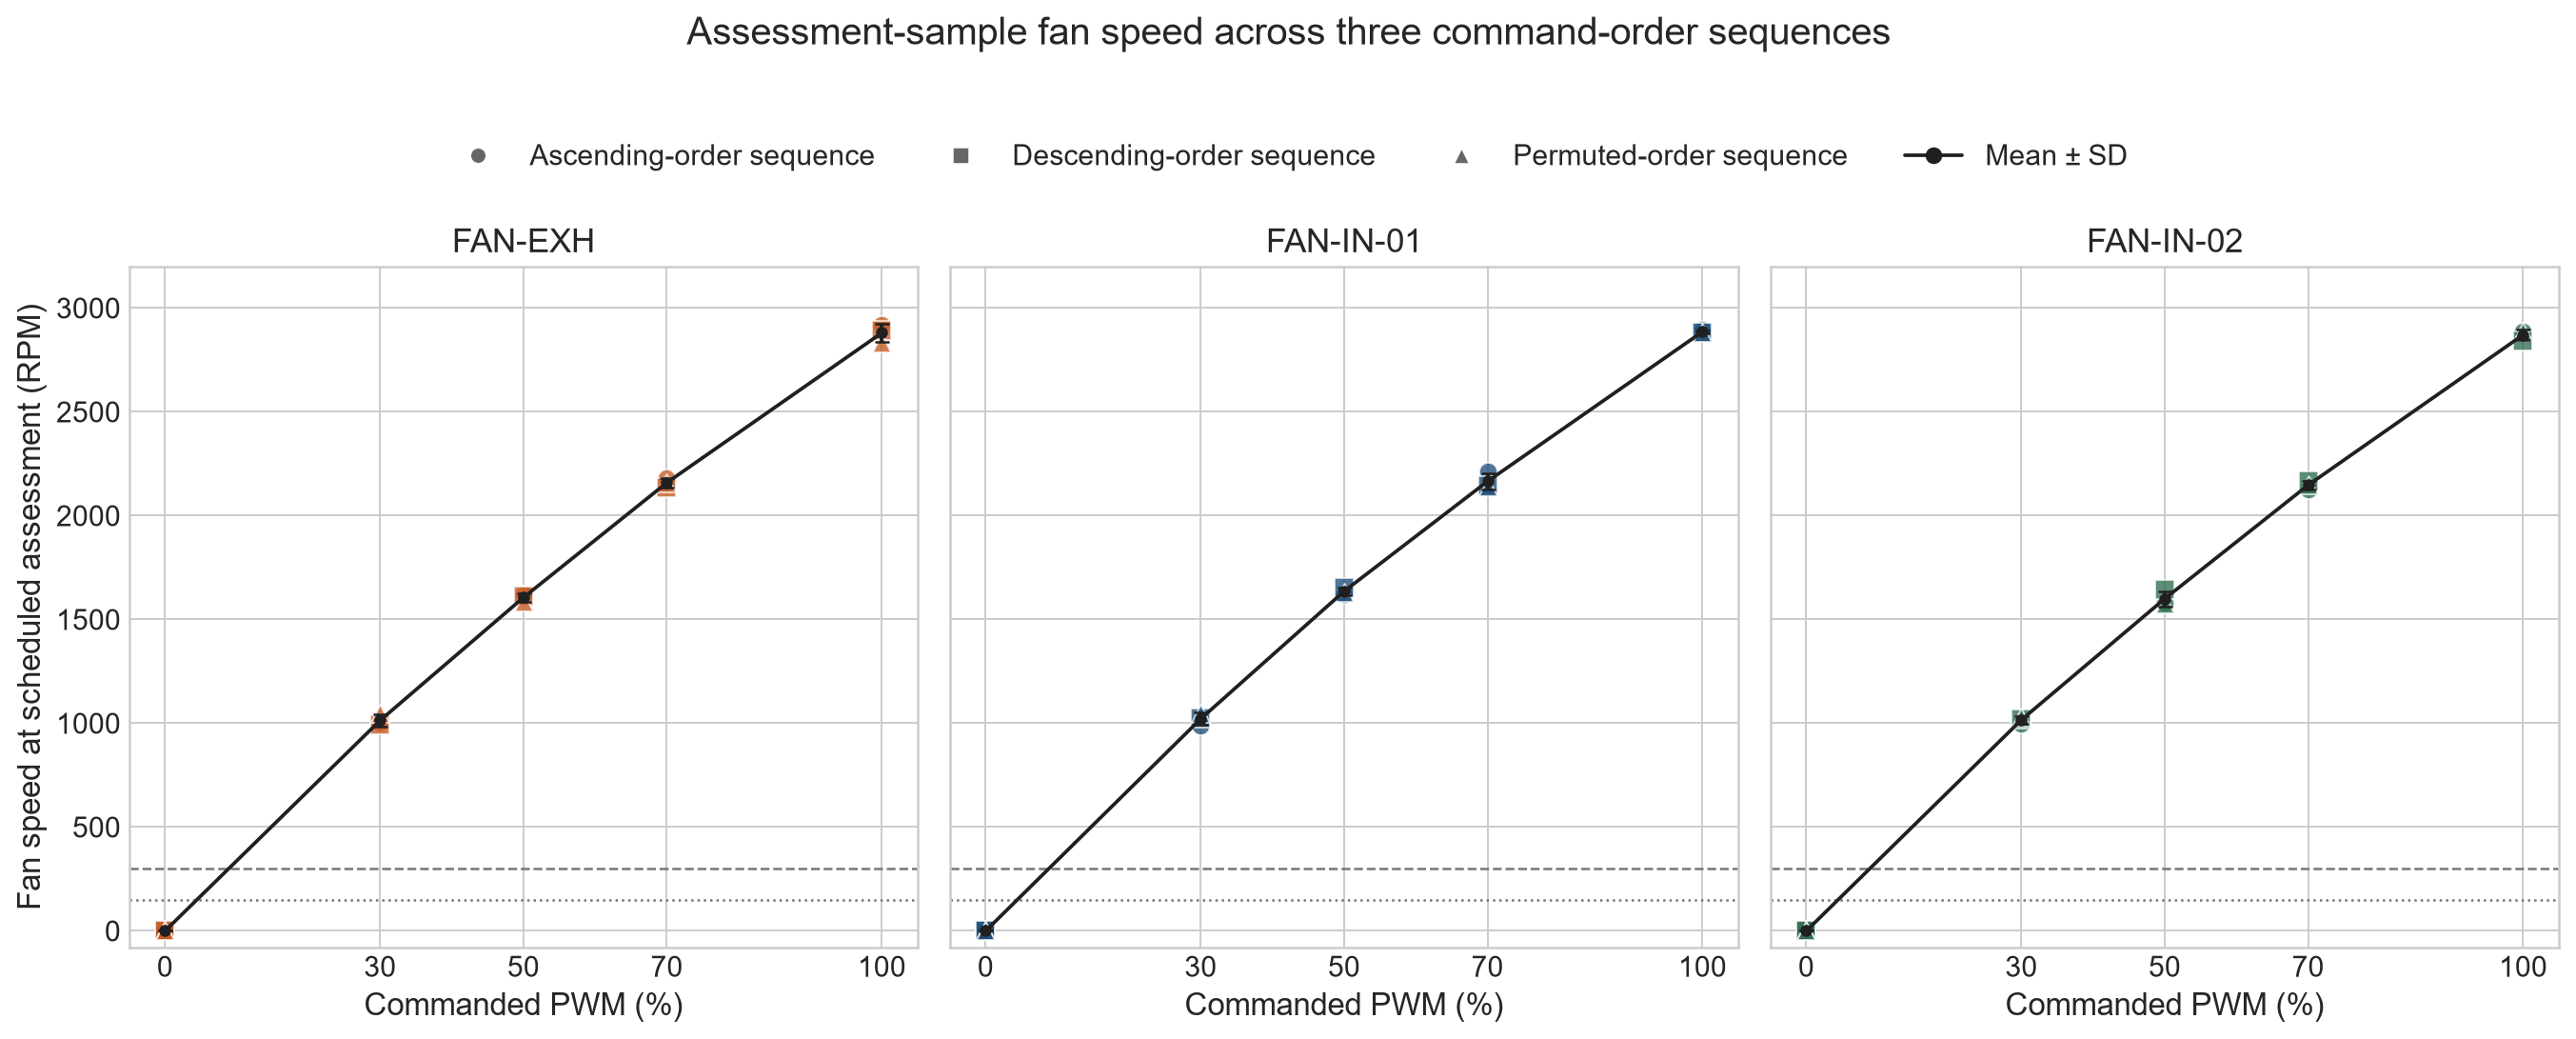

### Acknowledgement and fan-response timing

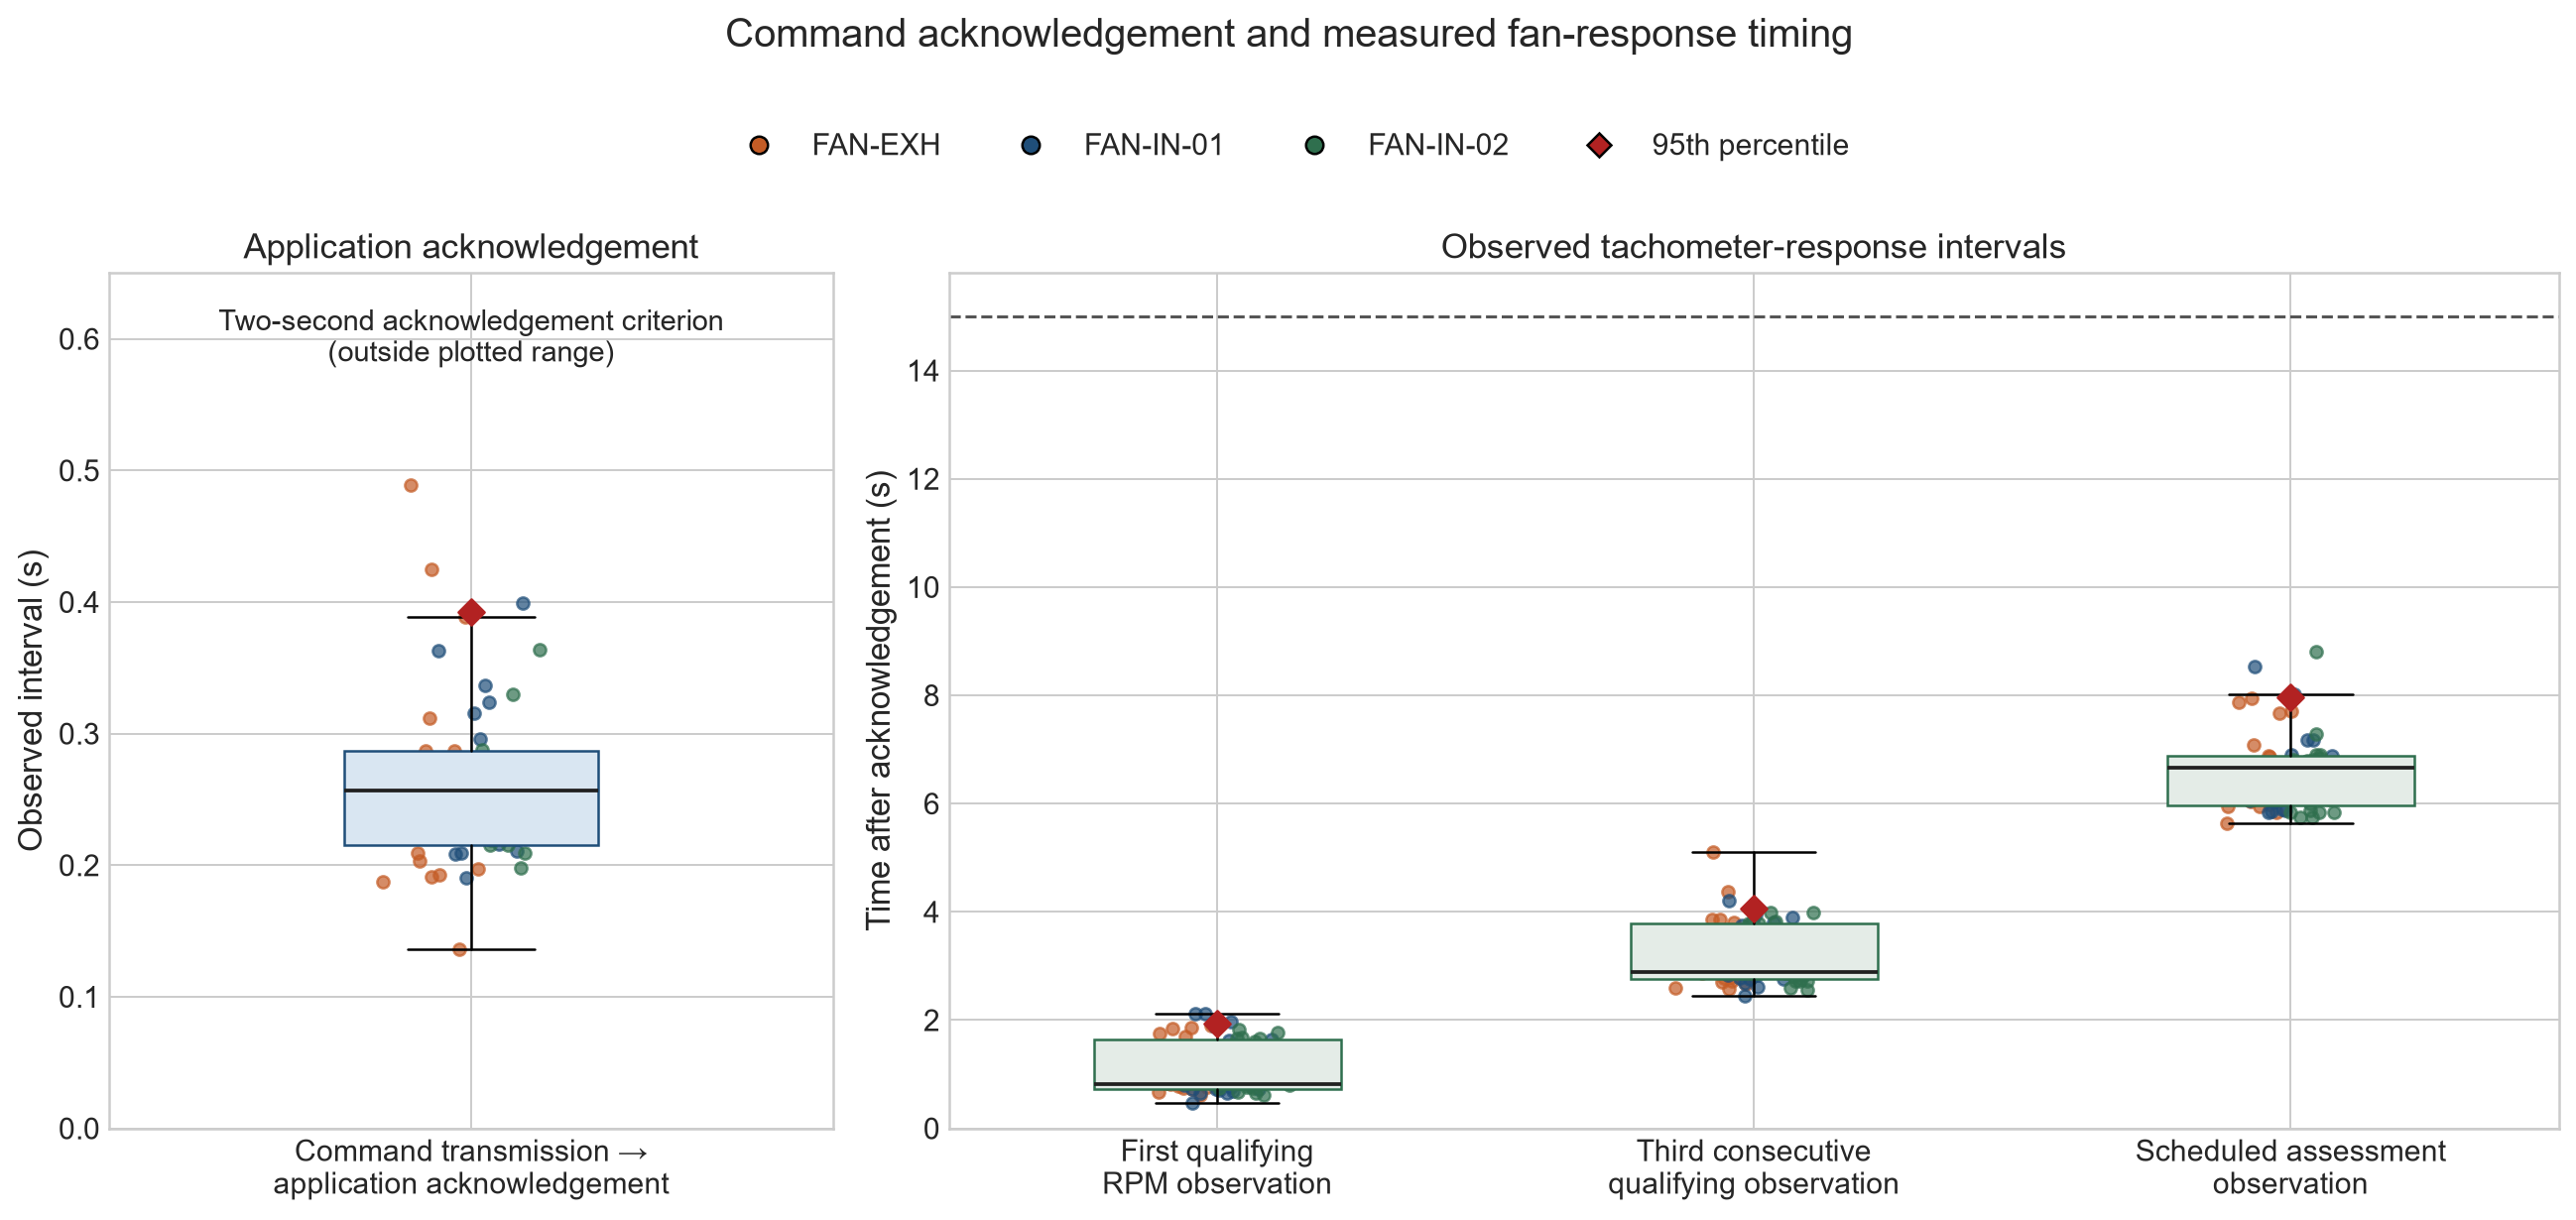

### Acknowledgement without exhaust-fan rotation

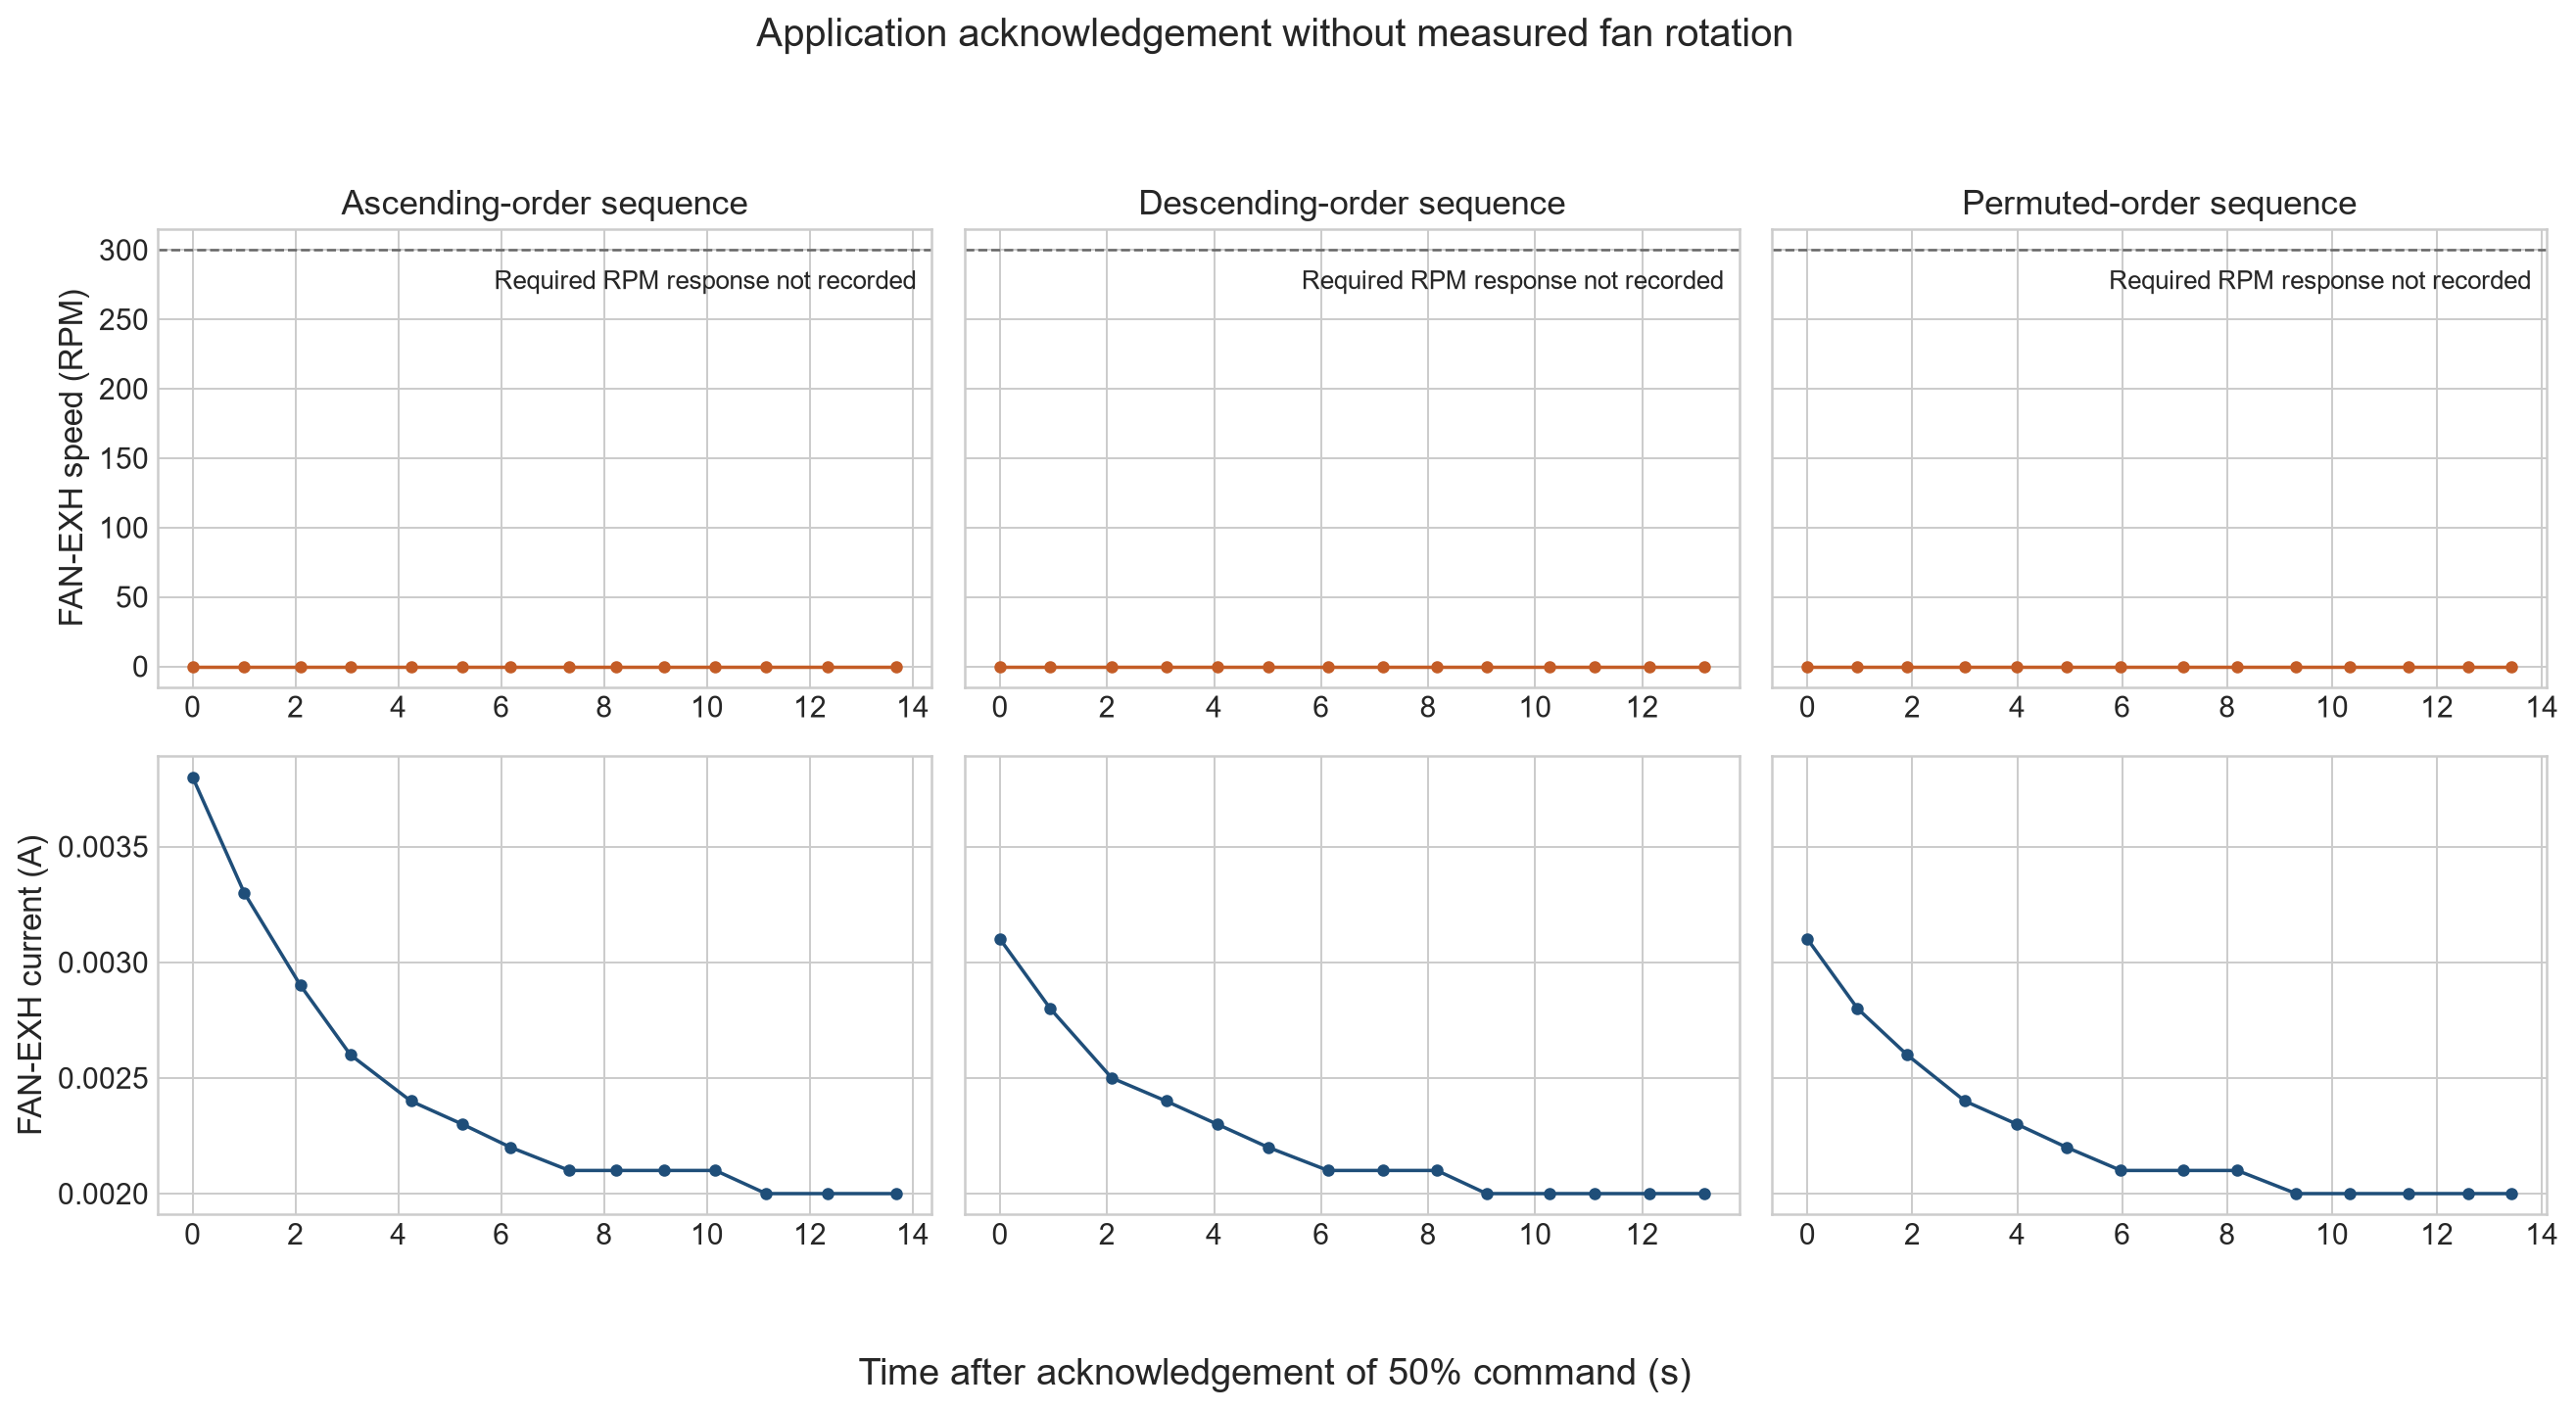

In [9]:
from indoortwin.evidence import display_plots
display_plots("07")
